# TP NLP — Détection **SPAM SMS** pipeline

**But** : classer un SMS en `spam` ou `ham`.
**Dataset** : *SMS Spam Collection* (UCI) via HuggingFace `datasets`
**Pipeline** : 1) Prétraitement  2) Représentation  3) Modélisation (≥2 modèles)  4) Évaluation + Analyse.

## 0) Installation

In [1]:
!pip -q install -U datasets scikit-learn matplotlib "pandas==2.2.2"
print("✅ Install OK")

## 1) Imports + seed

In [2]:
import re, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, learning_curve
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay

SEED=17; random.seed(SEED); np.random.seed(SEED)

## 2) Données — SMS Spam Collection

In [3]:
ds = load_dataset("sms_spam")
import pandas as pd
df = pd.DataFrame(ds['train']).rename(columns={'sms':'text'})[['text','label']].dropna().reset_index(drop=True)
df['label'] = df['label'].astype(int)
print(df.head()); print("\nRépartition:", df['label'].value_counts(normalize=True).round(3))

README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/359k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/5574 [00:00<?, ? examples/s]

                                                text  label
0  Go until jurong point, crazy.. Available only ...      0
1                    Ok lar... Joking wif u oni...\n      0
2  Free entry in 2 a wkly comp to win FA Cup fina...      1
3  U dun say so early hor... U c already then say...      0
4  Nah I don't think he goes to usf, he lives aro...      0

Répartition: label
0    0.866
1    0.134
Name: proportion, dtype: float64


## 3) Mini-aperçu

Taille: 5574  | longueur moyenne (mots): 15.6


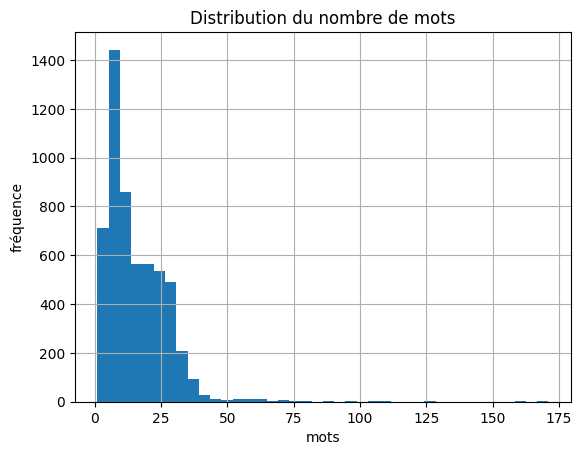

In [4]:
df['n_words'] = df['text'].str.split().apply(len)
print("Taille:", len(df), " | longueur moyenne (mots):", round(df['n_words'].mean(),1))
plt.figure(); df['n_words'].hist(bins=40); plt.title("Distribution du nombre de mots"); plt.xlabel("mots"); plt.ylabel("fréquence"); plt.show()

## 4) Prétraitement

In [5]:
URL=re.compile(r"https?://\S+|www\.\S+"); EMAIL=re.compile(r"\S+@\S+"); DIGIT=re.compile(r"\b\d+\b")
def clean_text(s: pd.Series)->pd.Series:
    out=[]
    for t in s.astype(str):
        t=t.lower(); t=URL.sub(" url ",t); t=EMAIL.sub(" email ",t); t=DIGIT.sub(" num ",t)
        t=re.sub(r"[^a-z\s]"," ",t); t=re.sub(r"\s+"," ",t).strip()
        out.append(t)
    return pd.Series(out)
clean_text(df['text'][:3])

,0
0,go until jurong point crazy available only in ...
1,ok lar joking wif u oni
2,free entry in num a wkly comp to win fa cup fi...


## 5) Train / Test split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['label'], test_size=0.2, random_state=SEED, stratify=df['label'])
len(X_train), len(X_test)

(4459, 1115)

## 6) Représentation + Modélisation

BoW + NaiveBayes -> Acc=0.983 | Precision=0.933 | Rappel=0.940 | F1=0.936


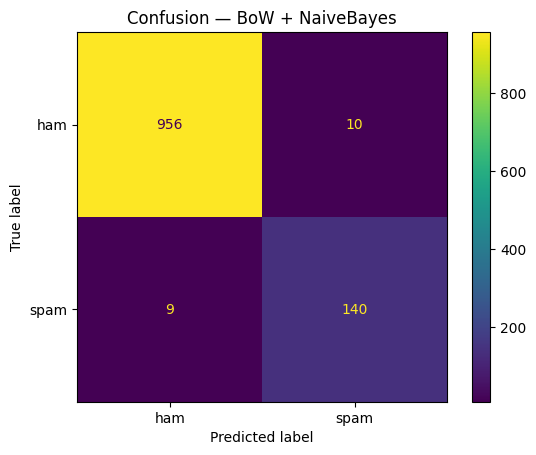

TF-IDF + LogReg -> Acc=0.963 | Precision=0.909 | Rappel=0.805 | F1=0.854


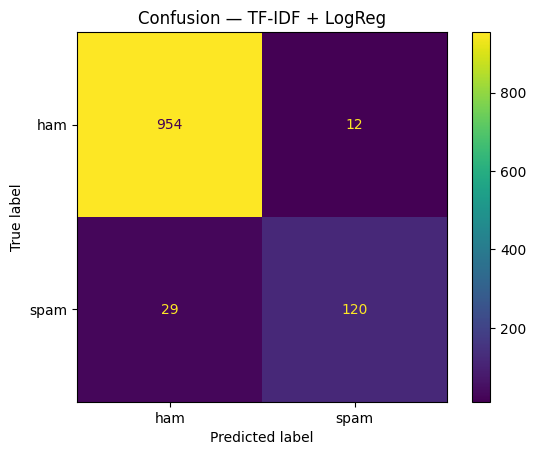

TF-IDF + LinearSVM -> Acc=0.983 | Precision=0.933 | Rappel=0.940 | F1=0.936


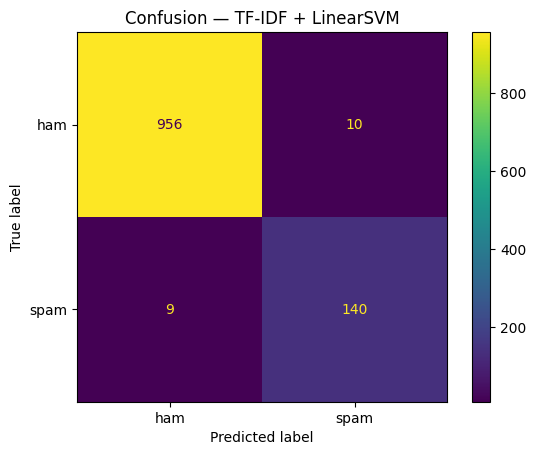


Résumé:
BoW + NaiveBayes     Acc=0.983 P=0.933 R=0.940 F1=0.936
TF-IDF + LogReg      Acc=0.963 P=0.909 R=0.805 F1=0.854
TF-IDF + LinearSVM   Acc=0.983 P=0.933 R=0.940 F1=0.936


[None, None, None]

In [7]:
cleaner=FunctionTransformer(clean_text)
pipelines={
 "BoW + NaiveBayes":Pipeline([("clean",cleaner),("vec",CountVectorizer(max_features=30000,ngram_range=(1,2),stop_words='english')),("clf",MultinomialNB())]),
 "TF-IDF + LogReg":Pipeline([("clean",cleaner),("tfidf",TfidfVectorizer(max_features=40000,ngram_range=(1,2),stop_words='english')),("clf",LogisticRegression(max_iter=300))]),
 "TF-IDF + LinearSVM":Pipeline([("clean",cleaner),("tfidf",TfidfVectorizer(max_features=40000,ngram_range=(1,2),stop_words='english')),("clf",LinearSVC())])
}
def evaluate(name,pipe):
    pipe.fit(X_train,y_train); pred=pipe.predict(X_test)
    acc=accuracy_score(y_test,pred); p,r,f1,_=precision_recall_fscore_support(y_test,pred,average='binary')
    print(f"{name} -> Acc={acc:.3f} | Precision={p:.3f} | Rappel={r:.3f} | F1={f1:.3f}")
    cm=confusion_matrix(y_test,pred); ConfusionMatrixDisplay(cm,display_labels=['ham','spam']).plot(values_format='d'); plt.title(f"Confusion — {name}"); plt.show()
    return acc,p,r,f1
scores={n:evaluate(n,p) for n,p in pipelines.items()}
print("\nRésumé:"); [print(f"{k:20s} Acc={a:.3f} P={pp:.3f} R={rr:.3f} F1={ff:.3f}") for k,(a,pp,rr,ff) in scores.items()]

## 7) Validation croisée

In [8]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
for name,pipe in pipelines.items():
    f1=cross_val_score(pipe,X_train,y_train,scoring='f1',cv=cv)
    print(f"{name:20s}  F1 CV: {f1.mean():.3f} ± {f1.std():.3f}")

BoW + NaiveBayes      F1 CV: 0.949 ± 0.026
TF-IDF + LogReg       F1 CV: 0.850 ± 0.028
TF-IDF + LinearSVM    F1 CV: 0.932 ± 0.021


## 8) GridSearchCV (TF-IDF + LogReg)

Best params: {'clf__C': 2.0, 'tfidf__max_features': 20000, 'tfidf__ngram_range': (1, 1)} | F1 CV: 0.897
Test (best) -> Acc=0.970  P=0.926  R=0.846  F1=0.884


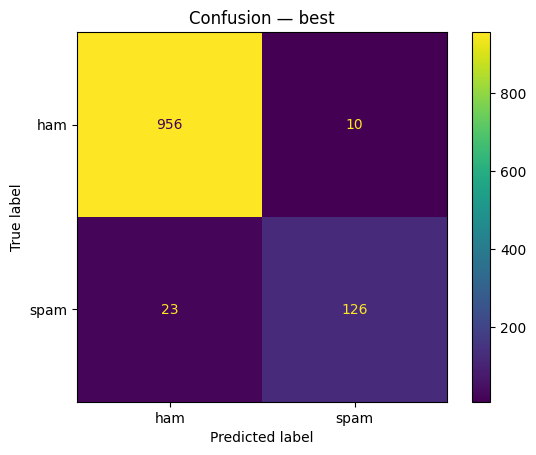

In [9]:
grid=Pipeline([("clean",cleaner),("tfidf",TfidfVectorizer(stop_words='english')),("clf",LogisticRegression(max_iter=400))])
params={"tfidf__ngram_range":[(1,1),(1,2)],"tfidf__max_features":[20000,40000,80000],"clf__C":[0.5,1.0,2.0]}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
gs=GridSearchCV(grid,params,scoring='f1',cv=cv); gs.fit(X_train,y_train)
print("Best params:",gs.best_params_,"| F1 CV:",round(gs.best_score_,3))
best=gs.best_estimator_
pred=best.predict(X_test); a=accuracy_score(y_test,pred); p,r,f1,_=precision_recall_fscore_support(y_test,pred,average='binary')
print(f"Test (best) -> Acc={a:.3f}  P={p:.3f}  R={r:.3f}  F1={f1:.3f}")
cm=confusion_matrix(y_test,pred); ConfusionMatrixDisplay(cm,display_labels=['ham','spam']).plot(values_format='d'); plt.title("Confusion — best"); plt.show()

## 9) ROC-AUC + Courbe d’apprentissage

AUC: 0.986


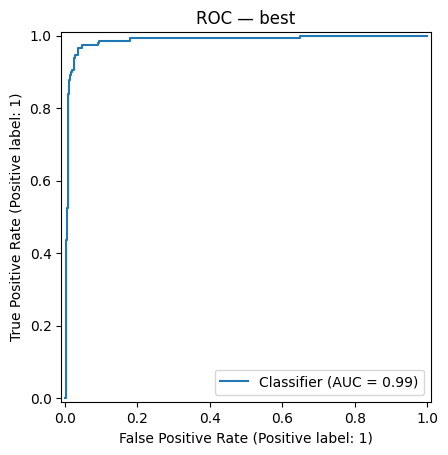

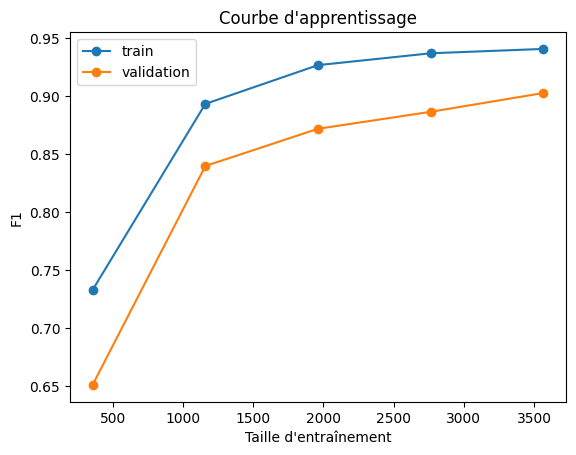

In [10]:
if hasattr(best.named_steps['clf'],'predict_proba'):
    scores_pos=best.predict_proba(X_test)[:,1]
    auc=roc_auc_score(y_test,scores_pos); print("AUC:",round(auc,3))
    RocCurveDisplay.from_predictions(y_test,scores_pos); plt.title("ROC — best"); plt.show()
sizes, tr, te = learning_curve(best, X_train, y_train, cv=5, scoring='f1', train_sizes=np.linspace(0.1,1.0,5))
plt.figure(); plt.plot(sizes,tr.mean(axis=1),marker='o',label='train'); plt.plot(sizes,te.mean(axis=1),marker='o',label='validation')
plt.xlabel("Taille d'entraînement"); plt.ylabel("F1"); plt.title("Courbe d'apprentissage"); plt.legend(); plt.show()

## 10) Analyse d’erreurs + export

In [11]:
res=pd.DataFrame({'text':X_test,'y_true':y_test,'y_pred':pred})
if 'scores_pos' in locals(): res['proba_spam']=scores_pos
fp=res[(res.y_true==0)&(res.y_pred==1)].head(10); fn=res[(res.y_true==1)&(res.y_pred==0)].head(10)
print("Faux positifs:"); display(fp); print("\nFaux négatifs:"); display(fn)
out="/mnt/data/predictions_sms_spam_pro.csv"; res.to_csv(out,index=False); print("Export:",out)

Faux positifs:


,text,y_true,y_pred,proba_spam
5175,U 2.\n,0,1,0.996602
5361,This is ur face test ( 1 2 3 4 5 6 7 8 9 &lt;...,0,1,0.952389
3307,HI DARLIN I FINISH AT 3 DO U 1 2 PICK ME UP OR...,0,1,0.528080
3291,My tuition is at 330. Hm we go for the 1120 to...,0,1,0.891038
1612,645\n,0,1,0.996602
2947,make that 3! 4 fucks sake?! x\n,0,1,0.952806
5238,Your opinion about me? 1. Over 2. Jada 3. Kusr...,0,1,0.654592
4678,Wewa is 130. Iriver 255. All 128 mb.\n,0,1,0.916353
4762,It's é only $140 ard...É rest all ard $180 at ...,0,1,0.789988
2933,Only 2% students solved this CAT question in '...,0,1,0.889033



Faux négatifs:


,text,y_true,y_pred,proba_spam
1460,Bought one ringtone and now getting texts cost...,1,0,0.368116
3443,Save money on wedding lingerie at www.bridal.p...,1,0,0.241973
1469,Hi its LUCY Hubby at meetins all day Fri & I w...,1,0,0.242902
4086,Orange brings you ringtones from all time Char...,1,0,0.458203
2364,Fantasy Football is back on your TV. Go to Sky...,1,0,0.262167
5100,TheMob>Hit the link to get a premium Pink Pant...,1,0,0.469382
2774,How come it takes so little time for a child w...,1,0,0.014141
2247,Hi ya babe x u 4goten bout me?' scammers getti...,1,0,0.034370
2003,TheMob>Yo yo yo-Here comes a new selection of ...,1,0,0.153138
1893,CALL 09090900040 & LISTEN TO EXTREME DIRTY LIV...,1,0,0.448357


## 11) Conclusion — pipeline validée
- **Prétraitement** : nettoyage reproductible.
- **Représentation** : BoW et **TF‑IDF**.
- **Modélisation** : Naive Bayes, LogReg, Linear SVM + **CV** et **GridSearch**.
- **Évaluation** : accuracy, précision, rappel, F1, matrices, ROC‑AUC, **learning curve**.
- **Analyse** : erreurs listées et exportées.